In [14]:
import numpy as np
from scipy import optimize
from scipy.stats import norm
import matplotlib.pyplot as plt

# Función Black-Scholes para calcular el precio de una opción de compra europea
def black_scholes_call(S, K, T, r, sigma):
    d1 = (np.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    call_price = S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return call_price

# Función para calcular la diferencia entre el precio de mercado y el precio teórico
def implied_volatility(sigma, S, K, T, r, market_price):
    model_price = black_scholes_call(S, K, T, r, sigma)
    return model_price - market_price

def implied_surface(K, alpha, beta, gamma):
    return alpha * K + beta * K ** 2 + gamma

In [220]:
# Datos de la opción
S = 100  # Precio del activo subyacente
K = 100  # Precio de ejercicio
T = 1.0  # Vencimiento en años
r = 0.05 # Tasa libre de riesgo
market_price = 8  # Precio de mercado de la opción

# Calculamos la volatilidad implícita
initial_guess = 0.2  # Suposición inicial de volatilidad
implied_vol = optimize.newton(implied_volatility, 
                              args=(S, K, T, r, market_price), 
                              x0=initial_guess)

print(f"Volatilidad Implícita: {implied_vol:.4f}")

Volatilidad Implícita: 0.1338


In [201]:
S = 100  # Precio del activo subyacente
T = 1.0  # Vencimiento en años
r = 0.05  # Tasa libre de riesgo
K = [80, 90, 100, 110, 120]
volatility_range = np.linspace(0.1, 0.9, 5)
[black_scholes_call(S,k, T, r, sigma) for (sigma, k) in zip(volatility_range,K)]

[23.90997789403842,
 19.69744208683972,
 21.79260421286685,
 25.739024616455765,
 30.48597779963444]

In [171]:
# Graficamos la superficie de volatilidad
volatility_range = np.linspace(0.01, 2.0, 100)
strikes = np.linspace(0.5, 1.5, 100)
volatility_range = [implied_surface(K, alpha=0.08, beta=0.05, gamma = 0.1 ) 
                    for K in strikes]
option_prices = [black_scholes_call(S, S*K, T, r, sigma) for (sigma, K) in zip(volatility_range,strikes)]
volatility_range[0]

0.15250000000000002

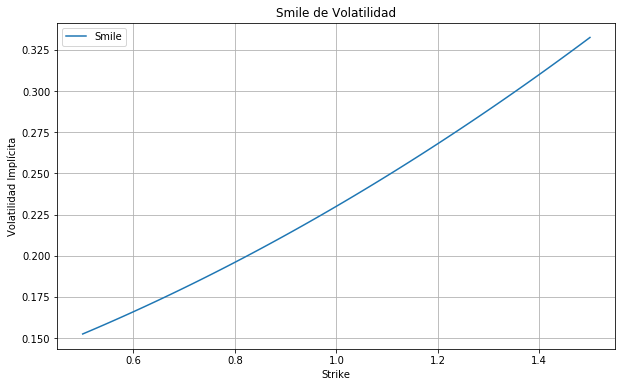

In [172]:
plt.figure(figsize=(10, 6))
plt.plot(strikes,volatility_range, label='Smile')
plt.ylabel('Volatilidad Implícita')
plt.xlabel('Strike')
plt.title('Smile de Volatilidad')
plt.legend()
plt.grid(True)
plt.show()

In [222]:
S = 100  # Precio del activo subyacente
T = 1.0  # Vencimiento en años
r = 0.05  # Tasa libre de riesgo
K = [80, 90, 100, 110, 120]
market_prices = [24,19.,21.,25.,30.]
x0 = 0.9
implied_vol = [optimize.newton(implied_volatility, 
                              args=(S, k, T, r, market_price), 
                               x0=initial_guess) for (k, market_price) in zip(K,market_prices)]

In [223]:
implied_vol

[0.13601024997650943,
 0.2779341044394547,
 0.47890022742230814,
 0.6807371530465116,
 0.8872624132636651]